# One-match NWSL data exploration

This notebook opens one match from disk. It needs no API call or credentials. Match data and executed notebook outputs are private to the CSAS 2027 Data Challenge. Clear outputs before sharing the notebook.

In [ ]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

MATCH_DIR = Path("data/nwsl/1093/2044623")
TABLES = {
    "On-ball engagements": "on_ball_engagements.csv",
    "Player possessions": "player_possessions.csv",
    "Passing options": "passing_options.csv",
    "Off-ball runs": "off_ball_runs.csv",
}


def local_file(name):
    path = MATCH_DIR / name
    if path.is_file():
        return path
    gzipped = path.with_suffix(path.suffix + ".gz")
    if gzipped.is_file():
        return gzipped
    raise FileNotFoundError(f"No local file for {path}")


events = {name: pd.read_csv(local_file(file), low_memory=False) for name, file in TABLES.items()}
with pd.io.common.get_handle(local_file("match.json"), "r", compression="infer") as handle:
    match = json.load(handle.handle)
frames = pd.read_json(local_file("tracking.jsonl"), lines=True, compression="infer", convert_dates=False)
engagements = events["On-ball engagements"]
possessions = events["Player possessions"]

summary = pd.DataFrame(
    [(name, *table.shape) for name, table in events.items()]
    + [("Tracking (frames)", *frames.shape)],
    columns=["Dataset", "Rows", "Columns"],
).set_index("Dataset")
display(summary)

,Rows,Columns
Dataset,,
On-ball engagements,824,143
Player possessions,796,209
Passing options,2086,147
Off-ball runs,393,118
Tracking (frames),60767,7


## What each event table contains

Event counts give a sense of each table's grain. Tracking is summarized separately because a tracking row represents a frame.

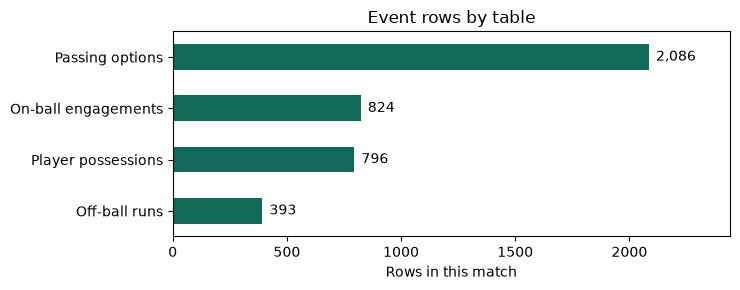

In [ ]:
counts = summary.drop("Tracking (frames)")["Rows"].sort_values()
ax = counts.plot.barh(figsize=(7.5, 3), color="#126a58", title="Event rows by table")
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=5)
ax.set(xlabel="Rows in this match", ylabel="", xlim=(0, counts.max() * 1.17))
plt.tight_layout()
plt.show()

## A first look at key columns

- **Possession duration** (`duration`) counts how many times a player held the ball for different lengths of time. Each histogram bar covers a range of seconds.
- **How possessions end** (`end_type`) counts the recorded ways a player stopped holding the ball, such as passing, shooting, or losing it.
- **Passing-option outcomes** (`targeted` and `received`) distinguish options the ball carrier did not choose from options they targeted, with or without a reception. The unit is a passing opportunity.
- **Off-ball run types** (`event_subtype`) count the kinds of runs teammates made without the ball.

The next section shows the corresponding subtype and duration plots for on-ball engagements. All charts describe this one match.

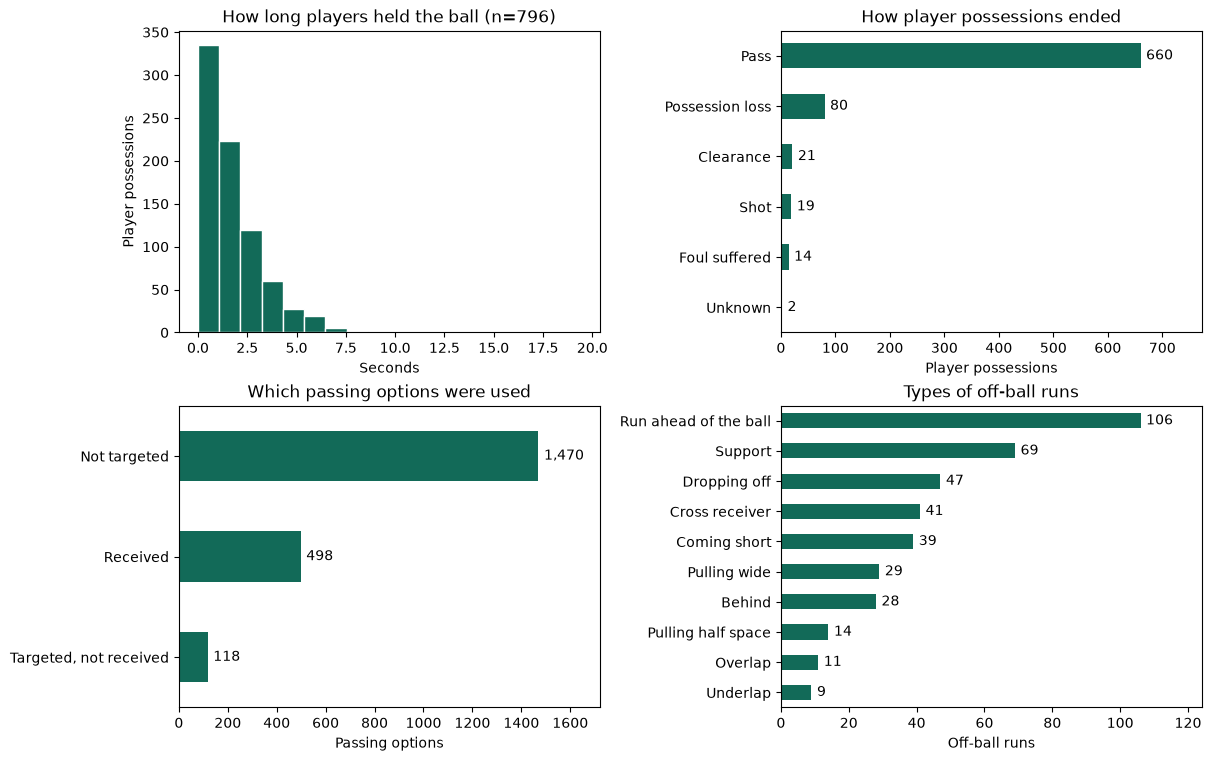

In [ ]:
possession_duration = pd.to_numeric(possessions["duration"], errors="coerce")
possession_duration = possession_duration[possession_duration.ge(0)]

possession_end_counts = (
    possessions["end_type"].fillna("unspecified")
    .str.replace("_", " ").str.capitalize().value_counts()
)
run_type_counts = (
    events["Off-ball runs"]["event_subtype"].fillna("unspecified")
    .str.replace("_", " ").str.capitalize().value_counts()
)

options = events["Passing options"]
targeted, received = options["targeted"], options["received"]
option_outcome = pd.Series("Unspecified", index=options.index, dtype="string")
option_outcome.loc[targeted.eq(False) & received.eq(False)] = "Not targeted"
option_outcome.loc[targeted.eq(True) & received.eq(False)] = "Targeted, not received"
option_outcome.loc[targeted.eq(True) & received.eq(True)] = "Received"
option_outcome.loc[targeted.eq(False) & received.eq(True)] = "Received, no target recorded"
option_counts = option_outcome.value_counts()

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), layout="constrained")
axes[0, 0].hist(possession_duration, bins=18, color="#126a58", edgecolor="white")
axes[0, 0].set(
    title=f"How long players held the ball (n={len(possession_duration):,})",
    xlabel="Seconds", ylabel="Player possessions",
)

for ax, values, title, xlabel in [
    (axes[0, 1], possession_end_counts, "How player possessions ended", "Player possessions"),
    (axes[1, 0], option_counts, "Which passing options were used", "Passing options"),
    (axes[1, 1], run_type_counts, "Types of off-ball runs", "Off-ball runs"),
]:
    values.sort_values().plot.barh(ax=ax, color="#126a58")
    ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=4)
    ax.set(title=title, xlabel=xlabel, ylabel="", xlim=(0, values.max() * 1.17))

plt.show()

## On-ball engagements

Compare how common the provider's engagement subtypes are and how long they tend to last. The duration plot uses rows with a valid nonnegative duration. The labels show the number of rows used for each box.

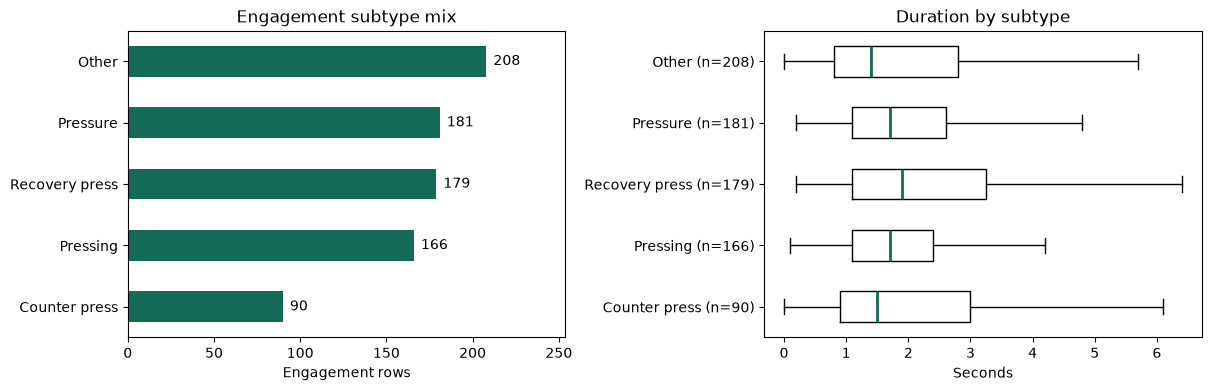

In [ ]:
subtypes = engagements["event_subtype"].fillna("unspecified").str.replace("_", " ").str.capitalize()
durations = pd.to_numeric(engagements["duration"], errors="coerce")
valid = durations.ge(0)
counts = subtypes.value_counts().sort_values()
duration_groups = durations[valid].groupby(subtypes[valid])

fig, (mix_ax, duration_ax) = plt.subplots(1, 2, figsize=(12, 3.8), layout="constrained")
counts.plot.barh(ax=mix_ax, color="#126a58")
mix_ax.bar_label(mix_ax.containers[0], fmt="{:,.0f}", padding=5)
mix_ax.set(title="Engagement subtype mix", xlabel="Engagement rows", ylabel="")
mix_ax.set_xlim(0, counts.max() * 1.22)

ordered = [label for label in counts.index if label in duration_groups.groups]
samples = [duration_groups.get_group(label) for label in ordered]
duration_ax.boxplot(
    samples,
    orientation="horizontal",
    tick_labels=[f"{label} (n={len(group):,})" for label, group in zip(ordered, samples)],
    showfliers=False,
    medianprops={"color": "#126a58", "linewidth": 2},
)
duration_ax.set(title="Duration by subtype", xlabel="Seconds")
plt.show()

## Check how events link to possessions and tracking

Check the possession event ID within this match. Separately, check whether each engagement's start occurs in the tracking file in the same period. A matching frame confirms that the frame exists and gives a starting point for checking player and ball visibility.

In [ ]:
assert possessions["event_id"].dropna().is_unique, "Expected one row per possession event ID."

possession_ids = possessions["event_id"].dropna()
with_link = engagements["associated_player_possession_event_id"].notna()
linked = engagements["associated_player_possession_event_id"].isin(possession_ids)

tracking_keys = pd.MultiIndex.from_frame(frames[["period", "frame"]])
start_keys = pd.MultiIndex.from_frame(engagements[["period", "frame_start"]])
with_start = engagements[["period", "frame_start"]].notna().all(axis=1)
tracked = start_keys.isin(tracking_keys) & with_start

checks = pd.DataFrame(
    {
        "Present": [with_link.sum(), linked.sum(), tracked.sum()],
        "Eligible": [len(engagements), with_link.sum(), with_start.sum()],
    },
    index=["Possession ID recorded", "Possession ID matched", "Start frame in tracking"],
)
checks["Share"] = checks["Present"].div(checks["Eligible"].where(checks["Eligible"].gt(0))).map("{:.1%}".format)
display(checks)

,Present,Eligible,Share
Possession ID recorded,824,824,100.0%
Possession ID matched,824,824,100.0%
Start frame in tracking,824,824,100.0%


## Compare possessions with and without recorded pressure

A possession is in the **Recorded pressure** group if it links to at least one on-ball engagement labeled `pressure`, `pressing`, `counter_press`, or `recovery_press`. The other group has no linked engagement with one of those labels. A passing option or off-ball run inherits the group of its linked possession. Rows that cannot be linked to a possession are left out.

Every panel shows percentages within each group. Passing options and runs are grouped by the whole possession, so they might occur before, during, or after the engagement. Longer possessions also give defenders more time to engage. Treat these plots as a description of one match.

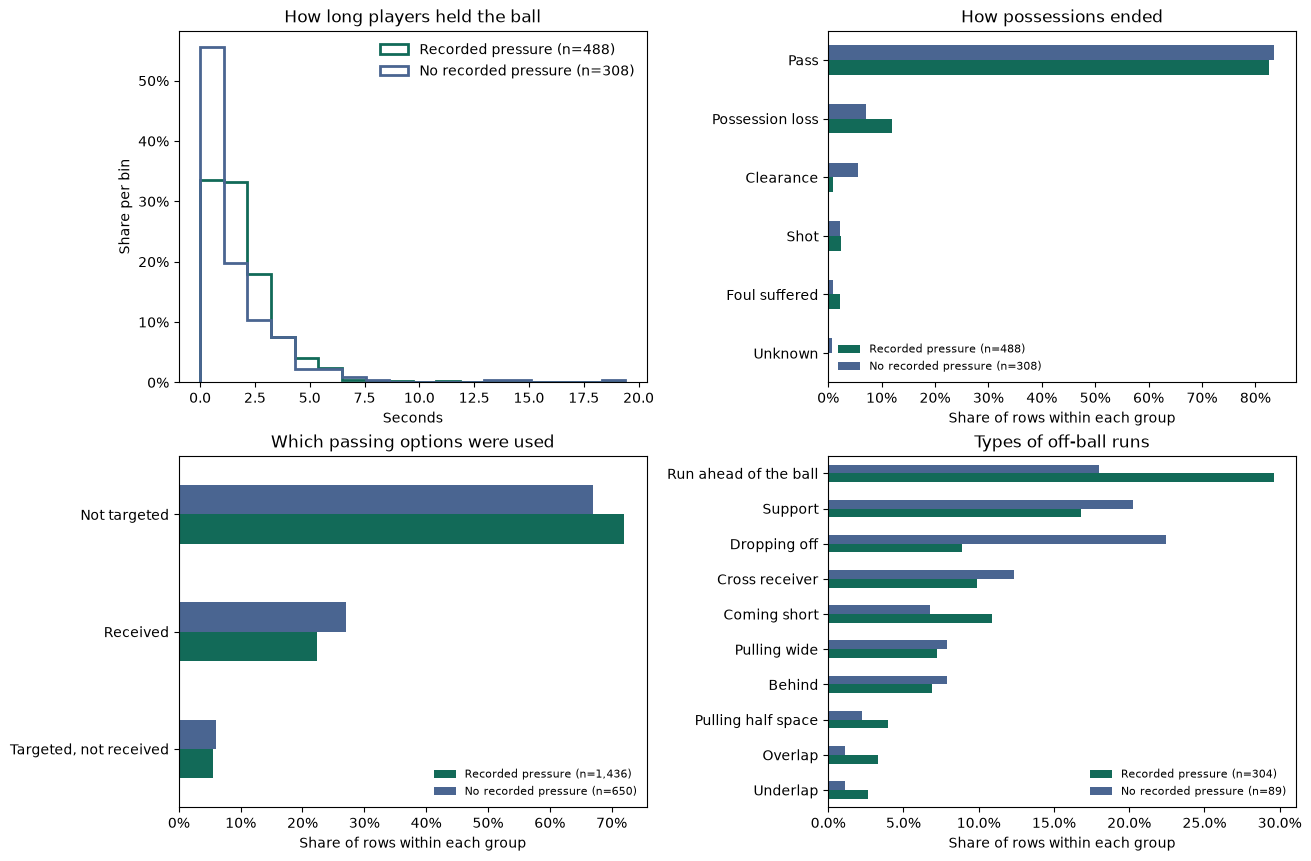

In [ ]:
import numpy as np
from matplotlib.ticker import PercentFormatter

pressure_types = {"pressure", "pressing", "counter_press", "recovery_press"}
link_column = "associated_player_possession_event_id"
pressure_ids = engagements.loc[linked & engagements["event_subtype"].isin(pressure_types), link_column]
pressure_group = pd.Series(
    np.where(possession_ids.isin(pressure_ids), "Recorded pressure", "No recorded pressure"),
    index=possession_ids,
)
possession_group = possessions["event_id"].map(pressure_group)
option_group = options[link_column].map(pressure_group)
runs = events["Off-ball runs"]
run_group = runs[link_column].map(pressure_group)

labels = ["Recorded pressure", "No recorded pressure"]
colors = ["#126a58", "#4a6591"]
fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), layout="constrained")

bins = np.histogram_bin_edges(possession_duration, bins=18)
for label, color in zip(labels, colors):
    seconds = possession_duration[possession_group.loc[possession_duration.index].eq(label)]
    if not seconds.empty:
        axes[0, 0].hist(
            seconds, bins=bins, weights=np.full(len(seconds), 1 / len(seconds)),
            histtype="step", linewidth=2, color=color, label=f"{label} (n={len(seconds):,})",
        )
axes[0, 0].set(title="How long players held the ball", xlabel="Seconds", ylabel="Share per bin")
axes[0, 0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0, 0].legend(frameon=False)

for ax, categories, group, title in [
    (axes[0, 1], possessions["end_type"], possession_group, "How possessions ended"),
    (axes[1, 0], option_outcome, option_group, "Which passing options were used"),
    (axes[1, 1], runs["event_subtype"], run_group, "Types of off-ball runs"),
]:
    category_labels = categories.fillna("unspecified").str.replace("_", " ").str.capitalize()
    counts_by_pressure = pd.crosstab(category_labels, group).reindex(columns=labels, fill_value=0)
    totals = counts_by_pressure.sum(axis=0)
    shares_by_pressure = counts_by_pressure.div(totals.where(totals.gt(0)), axis=1)
    order = counts_by_pressure.sum(axis=1).sort_values().index
    shares_by_pressure.columns = [f"{label} (n={totals[label]:,})" for label in labels]
    shares_by_pressure.loc[order].plot.barh(ax=ax, color=colors)
    ax.set(title=title, xlabel="Share of rows within each group", ylabel="")
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.legend(frameon=False, fontsize=8)

plt.show()

## Engagements by score state

SkillCorner records whether the team making the engagement was trailing, tied, or leading. Compare the subtype mix within each state. The sample sizes are engagement counts. To compare how frequently teams engage, we would also need the time or possession opportunities available in each state.

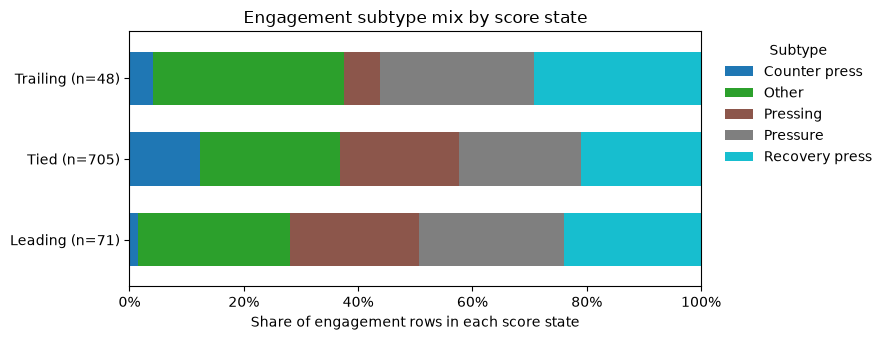

In [ ]:
from matplotlib.ticker import PercentFormatter

state_labels = {"losing": "Trailing", "drawing": "Tied", "winning": "Leading"}
state = engagements["game_state"].map(state_labels).fillna("Unspecified")
state_order = [label for label in [*state_labels.values(), "Unspecified"] if label in state.values]
mix = pd.crosstab(state, subtypes).reindex(state_order)
totals = mix.sum(axis=1)
shares = mix.div(totals, axis=0)
shares.index = [f"{label} (n={count:,})" for label, count in totals.items()]
ax = shares.plot.barh(
    stacked=True, figsize=(9, 3.5), colormap="tab10", width=0.66,
    title="Engagement subtype mix by score state",
)
ax.invert_yaxis()
ax.set(xlabel="Share of engagement rows in each score state", ylabel="", xlim=(0, 1))
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.legend(title="Subtype", bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

## Where engagements start on the pitch

This schematic counts engagement start locations using SkillCorner's recorded pitch third and channel. It describes the engaging player's location. The plot pools both teams in team-relative zones. The grid is schematic and displays aggregates only.

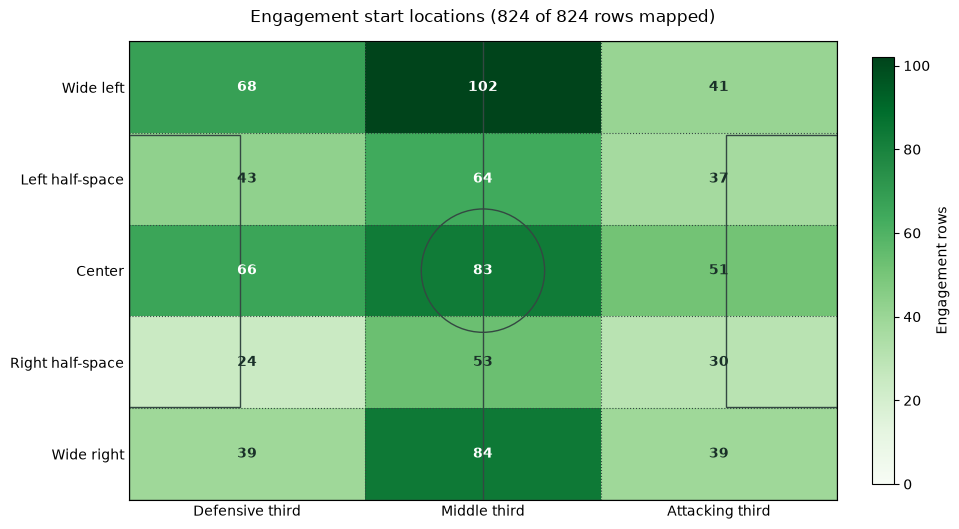

In [ ]:
from matplotlib.patches import Circle, Rectangle

thirds = ["defensive_third", "middle_third", "attacking_third"]
channels = ["wide_right", "half_space_right", "center", "half_space_left", "wide_left"]
zones = pd.crosstab(engagements["channel_start"], engagements["third_start"]).reindex(
    index=channels, columns=thirds, fill_value=0
)
mapped = int(zones.to_numpy().sum())

fig, ax = plt.subplots(figsize=(9.5, 5.7), layout="constrained")
field = ax.imshow(
    zones, origin="lower", extent=(0, 105, 0, 68),
    cmap="Greens", vmin=0, aspect="equal",
)
line = {"edgecolor": "#344842", "facecolor": "none", "linewidth": 1}
ax.add_patch(Rectangle((0, 0), 105, 68, **line))
ax.add_patch(Circle((52.5, 34), 9.15, **line))
ax.axvline(52.5, color="#344842", linewidth=1)
for left in (0, 88.5):
    ax.add_patch(Rectangle((left, 13.84), 16.5, 40.32, **line))

ax.vlines([35, 70], 0, 68, color="#344842", linestyle=":", linewidth=0.8)
ax.hlines([i * 68 / 5 for i in range(1, 5)], 0, 105,
          color="#344842", linestyle=":", linewidth=0.8)
for channel_index, row in enumerate(zones.to_numpy()):
    for third_index, count in enumerate(row):
        color = "white" if field.norm(count) > 0.57 else "#1a3029"
        ax.text((third_index + 0.5) * 35, (channel_index + 0.5) * 68 / 5,
                str(count), ha="center", va="center", color=color, fontweight="bold")

ax.set_xticks([17.5, 52.5, 87.5], ["Defensive third", "Middle third", "Attacking third"])
ax.set_yticks([(i + 0.5) * 68 / 5 for i in range(5)],
              ["Wide right", "Right half-space", "Center", "Left half-space", "Wide left"])
ax.tick_params(length=0)
ax.set_title(f"Engagement start locations ({mapped:,} of {len(engagements):,} rows mapped)", pad=14)
fig.colorbar(field, ax=ax, shrink=0.76, label="Engagement rows")
plt.show()

## How distance to the ball carrier changes

For rows with both distances recorded, subtract the distance at the start from the distance at the end. Negative values mean the two players ended closer together. This is a descriptive change for an engagement. It can reflect movement by either player.

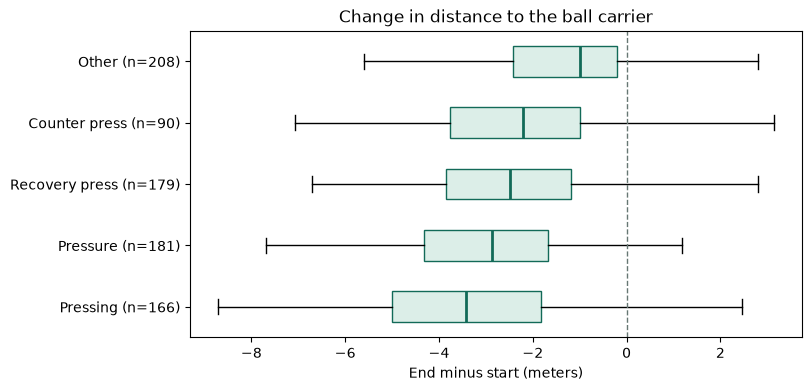

In [ ]:
distance_start = pd.to_numeric(engagements["interplayer_distance_start"], errors="coerce")
distance_end = pd.to_numeric(engagements["interplayer_distance_end"], errors="coerce")
valid_distance = distance_start.ge(0) & distance_end.ge(0)
distance_change = (distance_end - distance_start)[valid_distance]
by_subtype = distance_change.groupby(subtypes[valid_distance])
ordered = by_subtype.median().sort_values().index
groups = [by_subtype.get_group(label) for label in ordered]

fig, ax = plt.subplots(figsize=(8, 3.8), layout="constrained")
ax.boxplot(
    groups,
    orientation="horizontal",
    tick_labels=[f"{label} (n={len(group):,})" for label, group in zip(ordered, groups)],
    showfliers=False,
    patch_artist=True,
    boxprops={"facecolor": "#dceee8", "edgecolor": "#126a58"},
    medianprops={"color": "#126a58", "linewidth": 2},
)
ax.axvline(0, color="#667773", linestyle="--", linewidth=1)
ax.set(title="Change in distance to the ball carrier", xlabel="End minus start (meters)")
plt.show()